# Student Performance - Exploratory Data Analysis

Explore the student score dataset, check data quality, compare score distributions, and visualize relationships between student attributes and scores.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
SCORE_COLUMNS = ["math_score", "reading_score", "writing_score"]

In [2]:
# Supports running from either the project root or the notebook folder.
data_candidates = [Path("data/stud.csv"), Path("notebook/data/stud.csv")]
DATA_PATH = next((path for path in data_candidates if path.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find stud.csv. Expected data/stud.csv or notebook/data/stud.csv."
    )

df = pd.read_csv(DATA_PATH)
missing_score_columns = set(SCORE_COLUMNS) - set(df.columns)
if missing_score_columns:
    raise ValueError(f"Dataset is missing score columns: {sorted(missing_score_columns)}")


print(f"Loaded {DATA_PATH}")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())

Loaded data\stud.csv
Rows: 1,000 | Columns: 8


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [3]:
print("Column types")
display(df.dtypes.rename("dtype").to_frame())

print("Summary statistics")
display(df.describe(include="all").T)

Column types


,dtype
gender,str
race_ethnicity,str
parental_level_of_education,str
lunch,str
test_preparation_course,str
math_score,int64
reading_score,int64
writing_score,int64


Summary statistics


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,1000,2,female,518,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race_ethnicity,1000,5,group C,319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
parental_level_of_education,1000,6,some college,226,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lunch,1000,2,standard,645,NaN,NaN,NaN,NaN,NaN,NaN,NaN
test_preparation_course,1000,2,none,642,NaN,NaN,NaN,NaN,NaN,NaN,NaN
math_score,1000.0,NaN,NaN,NaN,66.089,15.16308,0.0,57.0,66.0,77.0,100.0
reading_score,1000.0,NaN,NaN,NaN,69.169,14.600192,17.0,59.0,70.0,79.0,100.0
writing_score,1000.0,NaN,NaN,NaN,68.054,15.195657,10.0,57.75,69.0,79.0,100.0


In [4]:
print("Missing values by column")
display(df.isna().sum().rename("missing_values").to_frame())
print(f"Duplicate rows: {df.duplicated().sum()}")

Missing values by column


,missing_values
gender,0
race_ethnicity,0
parental_level_of_education,0
lunch,0
test_preparation_course,0
math_score,0
reading_score,0
writing_score,0


Duplicate rows: 0


## Categorical feature distributions

In [5]:
categorical_columns = df.select_dtypes(include="object").columns.tolist()
for column in categorical_columns:
    print(f"\n{column}")
    display(df[column].value_counts(dropna=False).rename("count").to_frame())


gender


C:\Users\admin\AppData\Local\Temp\ipykernel_20640\575462176.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns.tolist()


,count
gender,
female,518
male,482



race_ethnicity


,count
race_ethnicity,
group C,319
group D,262
group B,190
group E,140
group A,89



parental_level_of_education


,count
parental_level_of_education,
some college,226
associate's degree,222
high school,196
some high school,179
bachelor's degree,118
master's degree,59



lunch


,count
lunch,
standard,645
free/reduced,355



test_preparation_course


,count
test_preparation_course,
none,642
completed,358


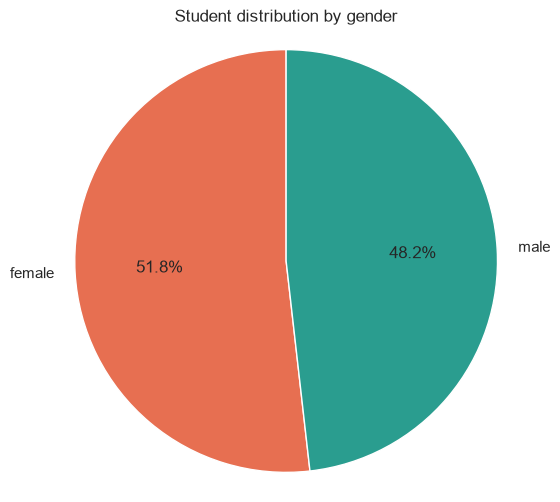

In [6]:
if "gender" in df.columns:
    gender_counts = df["gender"].value_counts()
    plt.figure(figsize=(6, 6))
    plt.pie(
        gender_counts.values,
        labels=gender_counts.index,
        autopct="%1.1f%%",
        startangle=90,
        colors=["#e76f51", "#2a9d8f", "#e9c46a", "#457b9d"],
    )
    plt.title("Student distribution by gender")
    plt.axis("equal")
    plt.show()
else:
    print("No gender column is available for the pie chart.")

## Score distributions and relationships

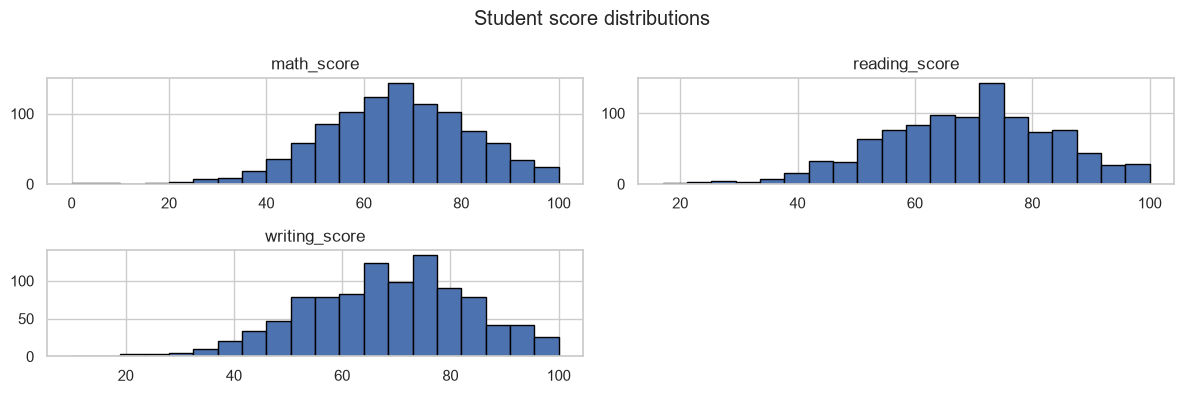

In [7]:
df[SCORE_COLUMNS].hist(bins=20, figsize=(12, 4), edgecolor="black")
plt.suptitle("Student score distributions")
plt.tight_layout()
plt.show()

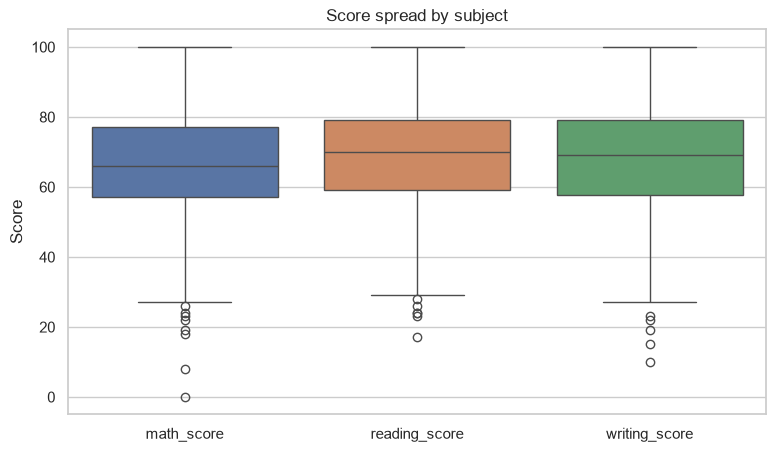

In [8]:
score_data = df.melt(
    value_vars=SCORE_COLUMNS,
    var_name="subject",
    value_name="score",
)
plt.figure(figsize=(9, 5))
sns.boxplot(data=score_data, x="subject", y="score", hue="subject", legend=False)
plt.title("Score spread by subject")
plt.xlabel("")
plt.ylabel("Score")
plt.show()

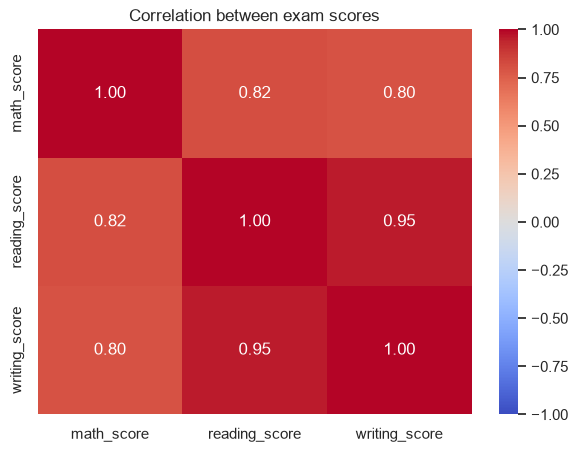

In [9]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    df[SCORE_COLUMNS].corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
)
plt.title("Correlation between exam scores")
plt.show()

In [10]:
for column in ["gender", "lunch", "test_preparation_course"]:
    if column in df.columns:
        print(f"Average scores by {column}")
        display(df.groupby(column, observed=True)[SCORE_COLUMNS].mean().round(1))

Average scores by gender


,math_score,reading_score,writing_score
gender,,,
female,63.6,72.6,72.5
male,68.7,65.5,63.3


Average scores by lunch


,math_score,reading_score,writing_score
lunch,,,
free/reduced,58.9,64.7,63.0
standard,70.0,71.7,70.8


Average scores by test_preparation_course


,math_score,reading_score,writing_score
test_preparation_course,,,
completed,69.7,73.9,74.4
none,64.1,66.5,64.5
